# 02 · Red densa frente a LSTM (escenario A: 10 géneros de GTZAN)

**Pregunta.** Con la misma entrada (segmentos de 5 s descritos por 13 MFCC), ¿clasifica mejor el
género una red que recorre el segmento en el tiempo (LSTM) que una red densa que lo ve aplanado?

**Protocolo.**

- Los dos modelos se entrenan con **los mismos segmentos**, normalizados con la media y la
  desviación del entrenamiento.
- La partición de GTZAN es *fault-filtered*: ningún artista está en dos particiones.
- La parada temprana se decide con la pérdida en **validación**. La prueba solo se evalúa al final.
- Los hiperparámetros (dropout y tasa de aprendizaje) se eligieron en validación con una rejilla
  pequeña. Cada configuración final se entrena con 3 semillas.
- Se reportan la exactitud por segmento y por canción. La predicción por canción es el voto de sus
  segmentos.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from generos import figuras, resultados as res
from generos.config import ESCENARIOS, NOMBRES

figuras.aplicar_estilo()
pd.set_option("display.precision", 3)

import json
from generos.config import RESULTS

corridas = res.cargar()
resumen = res.resumen(corridas)

## Elección de hiperparámetros (solo validación, semilla 0)

In [2]:
busqueda = res.tabla_busqueda()
for c in ("Validación (segmento)", "Validación (canción)"):
    busqueda[c] = busqueda[c].map(res.pct)
busqueda["Tasa"] = busqueda["Tasa"].map(lambda v: f"{v:g}")
busqueda.rename(columns={"Épocas": "Mejor época"}).set_index(["Modelo", "Dropout", "Tasa"])

Mejor época Validación (segmento)  \
Modelo    Dropout Tasa                                        
LSTM      0.3     0.0003            2                  31,8   
                  0.001             1                  30,7   
          0.5     0.0003            2                  31,0   
                  0.001             2                  35,8   
Red densa 0.3     0.0003            2                  32,4   
                  0.001             1                  35,1   
          0.5     0.0003            4                  36,4   
                  0.001             3                  34,9   

                         Validación (canción)  
Modelo    Dropout Tasa                         
LSTM      0.3     0.0003                 32,5  
                  0.001                  29,4  
          0.5     0.0003                 31,0  
                  0.001                  37,1  
Red densa 0.3     0.0003                 33,5  
                  0.001                  38,1  
          0.5     0.0003                 39,6  
                  0.001                  34,5

In [3]:
elegidos = res.elegidos()
for m, hp in elegidos.items():
    print(f"{res.MODELOS[m]}: dropout {hp['dropout']}, tasa {hp['tasa']}")

Red densa: dropout 0.5, tasa 0.0003
LSTM: dropout 0.5, tasa 0.001


## Curvas de entrenamiento (semilla 0)

La línea gris es el entrenamiento; la de color, la validación. La línea vertical marca la época que
conserva la parada temprana.

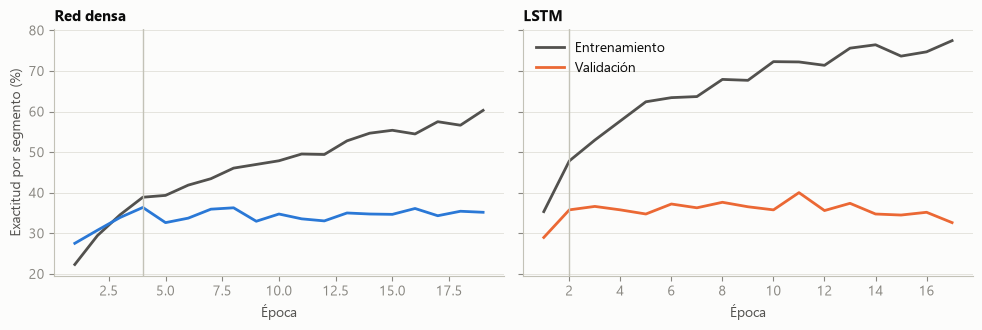

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, m in zip(ejes, res.MODELOS):
    r = next(r for r in corridas if r["escenario"] == "A" and r["modelo"] == m and r["semilla"] == 0)
    h = r["historia"]
    epocas = np.arange(1, len(h["accuracy"]) + 1)
    ax.plot(epocas, 100 * np.array(h["accuracy"]), color=figuras.TINTA_2, lw=2, label="Entrenamiento")
    ax.plot(epocas, 100 * np.array(h["val_accuracy"]), color=figuras.COLORES[m], lw=2, label="Validación")
    ax.axvline(r["mejor_epoca"], color=figuras.EJE, lw=1)
    ax.set_title(res.MODELOS[m])
    ax.set_xlabel("Época")
    ax.yaxis.grid(True)
ejes[0].set_ylabel("Exactitud por segmento (%)")
ejes[1].legend(loc="upper left")
fig.tight_layout()

In [5]:
for m in res.MODELOS:
    rs = [r for r in corridas if r["escenario"] == "A" and r["modelo"] == m]
    final_train = np.mean([r["historia"]["accuracy"][-1] for r in rs])
    mejor_valid = np.mean([max(r["historia"]["val_accuracy"]) for r in rs])
    print(f"{res.MODELOS[m]}: mejor época media {np.mean([r['mejor_epoca'] for r in rs]):.1f}; "
          f"exactitud de entrenamiento al final {100 * final_train:.1f} %; "
          f"máxima en validación {100 * mejor_valid:.1f} %")

Red densa: mejor época media 7.3; exactitud de entrenamiento al final 61.7 %; máxima en validación 35.4 %
LSTM: mejor época media 1.3; exactitud de entrenamiento al final 73.8 %; máxima en validación 38.6 %


## Resultado en prueba (media ± desviación entre 3 semillas)

In [6]:
def tabla(e):
    t = resumen[resumen["escenario"] == e].copy()
    t["Modelo"] = t["modelo"].map(res.MODELOS)
    t["Por segmento (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["segmento_media"], t["segmento_de"])]
    t["Por canción (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["cancion_media"], t["cancion_de"])]
    t["Parámetros"] = t["parametros"].map(res.miles)
    return t.set_index("Modelo")[["Parámetros", "Por segmento (%)", "Por canción (%)"]]

tabla("A")

,Parámetros,Por segmento (%),Por canción (%)
Modelo,,,
Red densa,368.458,"36,2 ± 0,8","38,5 ± 3,2"
LSTM,126.922,"33,2 ± 1,8","35,9 ± 2,1"


In [7]:
a = resumen[resumen["escenario"] == "A"].set_index("modelo")
dif = a.loc["lstm", "cancion_media"] - a.loc["densa", "cancion_media"]
print(f"Diferencia LSTM − densa por canción: {100 * dif:+.1f} puntos "
      f"(desviaciones entre semillas: densa {100 * a.loc['densa', 'cancion_de']:.1f}, LSTM {100 * a.loc['lstm', 'cancion_de']:.1f})")
print(f"Azar con 10 géneros: 10 %")

Diferencia LSTM − densa por canción: -2.6 puntos (desviaciones entre semillas: densa 3.2, LSTM 2.1)
Azar con 10 géneros: 10 %


**La LSTM no supera a la red densa.** Por canción, la densa acierta el 38,5 ± 3,2 % y la LSTM el
35,9 ± 2,1 %. La diferencia, −2,6 puntos, es del mismo orden que la variación entre semillas, así
que con estos datos no se puede afirmar que una arquitectura sea mejor que la otra. Por segmento la
densa también queda arriba (36,2 frente a 33,2 %). Ambas superan con holgura el azar (10 %).

Las curvas explican el nivel de las cifras:

- La exactitud de entrenamiento sigue subiendo: en la última época llega al 62 % en la densa y al
  74 % en la LSTM.
- La de validación se estanca entre el 35 % y el 39 % desde el principio.
- La LSTM alcanza su menor pérdida de validación en la primera o segunda época.

Con artistas distintos en cada partición, lo que los modelos memorizan de las canciones de
entrenamiento casi no se traslada a canciones nuevas. Una partición por segmentos, con trozos de la
misma canción en entrenamiento y en prueba, ocultaría este problema y daría cifras mucho más altas.

## ¿Dónde se equivoca? Matrices de confusión por canción (3 semillas sumadas)

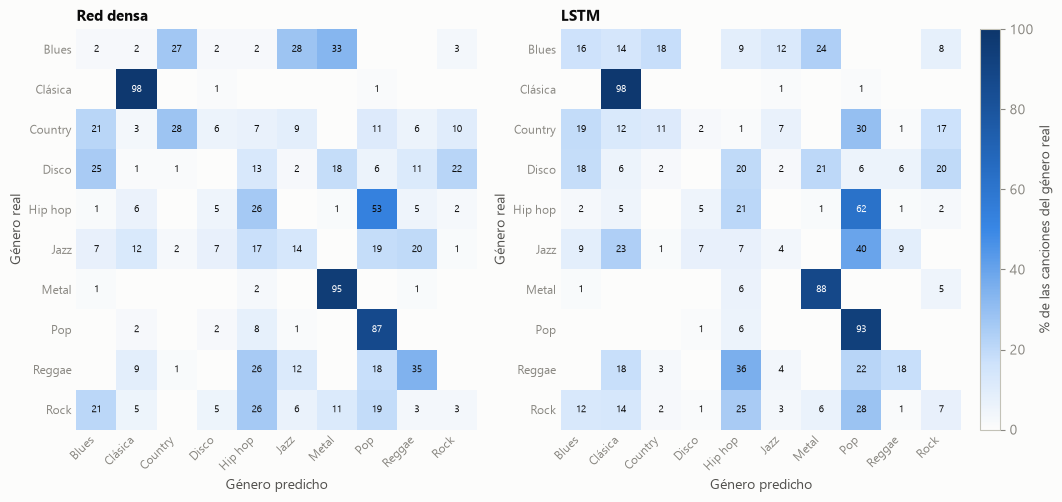

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, m in zip(ejes, res.MODELOS):
    cm, generos = res.confusion_media("A", m)
    im = figuras.confusion(cm, generos, res.MODELOS[m], ax=ax)
fig.colorbar(im, ax=ejes, fraction=0.025, pad=0.02, label="% de las canciones del género real");

In [9]:
sens = res.sensibilidad_por_genero("A")
(100 * sens).round(0).sort_values("LSTM", ascending=False)

,Red densa,LSTM
Clásica,98.0,98.0
Pop,87.0,93.0
Metal,95.0,88.0
Hip hop,26.0,21.0
Reggae,35.0,18.0
Blues,2.0,16.0
Country,28.0,11.0
Rock,3.0,7.0
Jazz,14.0,4.0
Disco,0.0,0.0


In [10]:
for m in res.MODELOS:
    cm, generos = res.confusion_media("A", m)
    errores = cm.copy()
    np.fill_diagonal(errores, 0)
    destino = pd.Series(errores.sum(0) / errores.sum(), index=[NOMBRES[g] for g in generos])
    print(f"{res.MODELOS[m]}, géneros que reciben más errores: "
          + ", ".join(f"{g} {100 * v:.0f} %" for g, v in destino.sort_values(ascending=False).head(3).items()))

Red densa, géneros que reciben más errores: Pop 21 %, Hip hop 16 %, Blues 13 %
LSTM, géneros que reciben más errores: Pop 29 %, Hip hop 17 %, Clásica 14 %


Los aciertos se concentran en tres géneros de timbre muy marcado: clásica (98 % con ambos modelos),
metal (95 y 88 %) y pop (87 y 93 %). Disco no se acierta nunca, y rock queda por debajo del 10 %.
Los errores van sobre todo a pop y a hip hop: los modelos usan esas clases como destino por defecto
cuando no reconocen el género.